# Task 2: Consumption and bill forecasting

**Goal:** predict future household consumption from past consumption and calendar features, then convert the prediction into an estimated monthly bill.

**Input:** `clean_energy.csv` (hourly UCI data, produced by Task 1).

**Plan:** baselines first, then Random Forest and XGBoost, tune a few parameters on validation, evaluate once on the test period, then build the 24-hour forecast model, the bill estimate and `predict.py`.

## 1. Setup

Imports, paths, and the settings used everywhere:
- `TARGET` is the hourly mean of `Global_active_power` (in kW, which equals kWh for one hour).
- `VAL_START` and `TEST_START` define the time-based split: train on the first 3 years, validate on the next 6 months, test on the rest.
- `RF_FINAL` and `XGB_FINAL` hold the model parameters. They start with default values and cell 7 replaces them with the best ones found on validation.
- `mae_rmse` and `report` compute and print MAE and RMSE so every model is measured the same way.

In [15]:
import importlib
import json
import sys
from itertools import product
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

REPO = Path.cwd().parent if Path.cwd().name == "energy" else Path.cwd()
OUT = REPO / "energy"
OUT.mkdir(exist_ok=True)
CLEAN_CSV = OUT / "clean_energy.csv"
assert CLEAN_CSV.exists(), f"{CLEAN_CSV} not found: run 01_clean_explore.ipynb first"

TARGET = "Global_active_power"          # kW, hourly mean (= kWh per hour)
VAL_START = pd.Timestamp("2009-12-01")  # train: before this (3 years)
TEST_START = pd.Timestamp("2010-06-01") # val: 6 months, test: the rest

# Starting values; cell 7 replaces them with the best ones found on validation
RF_FINAL = dict(n_estimators=300, min_samples_leaf=5, max_depth=None,
                n_jobs=-1, random_state=42)
XGB_FINAL = dict(n_estimators=500, learning_rate=0.05, max_depth=5,
                 subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42)


def mae_rmse(y_true, y_pred):
    return (mean_absolute_error(y_true, y_pred),
            float(np.sqrt(mean_squared_error(y_true, y_pred))))


def report(name, y_true, y_pred):
    mae, rmse = mae_rmse(y_true, y_pred)
    print(f"{name:34s} MAE={mae:.4f}  RMSE={rmse:.4f}")

## 2. Load the clean data

Read `clean_energy.csv` from Task 1. Task 1 dropped long gaps, so the time index is not continuous. `asfreq("1h")` puts the missing hours back as `NaN`, so that `shift(24)` really means "the same hour yesterday" and not "24 rows back".

In [16]:
df = pd.read_csv(CLEAN_CSV, index_col=0, parse_dates=True)
assert TARGET in df.columns, df.columns.tolist()
print("loaded:", df.shape, df.index.min(), "->", df.index.max())

# Task 1 dropped long gaps, so the index is not continuous. Put the missing hours back
# as NaN so that shift(24) really means "same hour yesterday".
df = df.asfreq("1h")
n_gap = int(df[TARGET].isna().sum())
print(f"after asfreq: {len(df):,} hours | hours missing (gaps from Task 1): {n_gap:,}")

loaded: (34169, 12) 2006-12-16 17:00:00 -> 2010-11-26 21:00:00
after asfreq: 34,589 hours | hours missing (gaps from Task 1): 420


## 3. Feature engineering

Features for predicting the next hour:
- Calendar: hour, day of week, is_weekend.
- Lags: consumption 1, 2, 24 and 168 hours ago (1 hour, 2 hours, yesterday, last week).
- Rolling means of the previous 24 and 168 hours (`shift(1)` first, so the current hour is never included).

Only the target's past and the calendar are used. The other columns in the CSV (voltage, current, sub-meters) are measured in the same hour we want to predict, so using them would leak the answer. Rows that touch a gap are dropped.

In [17]:
feat = df[[TARGET]].copy()
feat["hour"] = feat.index.hour
feat["weekday"] = feat.index.day_of_week
feat["is_weekend"] = (feat["weekday"] >= 5).astype(int)

for lag in [1, 2, 24, 168]:
    feat[f"lag_{lag}"] = feat[TARGET].shift(lag)
feat["roll_24"] = feat[TARGET].shift(1).rolling(24).mean()
feat["roll_168"] = feat[TARGET].shift(1).rolling(168).mean()

# only calendar + past values of the target (other columns of the CSV would leak the answer)
FEATURES = [c for c in feat.columns if c != TARGET]
df_model = feat.dropna().copy()     # rows touching a gap are dropped here
print(df_model.shape, "| features:", FEATURES)

(32825, 10) | features: ['hour', 'weekday', 'is_weekend', 'lag_1', 'lag_2', 'lag_24', 'lag_168', 'roll_24', 'roll_168']


## 4. Time-based split

Train, validation and test are cut by date, never randomly. A random split would put hours from the future in the training set and make the results look unrealistically good.

In [18]:
train = df_model[df_model.index < VAL_START]
val   = df_model[(df_model.index >= VAL_START) & (df_model.index < TEST_START)]
test  = df_model[df_model.index >= TEST_START]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s}: {len(part):6d} rows | {part.index.min()} -> {part.index.max()}")

train:  25126 rows | 2006-12-23 17:00:00 -> 2009-11-30 23:00:00
val  :   3947 rows | 2009-12-01 00:00:00 -> 2010-05-31 23:00:00
test :   3752 rows | 2010-06-01 00:00:00 -> 2010-11-26 21:00:00


## 5. Naive baselines

Two simple rules the models must beat: "same hour yesterday" and "same hour last week". Any model that cannot beat these is not useful. The error is recorded on the test period.

In [19]:
report("Baseline: same hour yesterday", test[TARGET], test["lag_24"])
report("Baseline: same hour last week", test[TARGET], test["lag_168"])

Baseline: same hour yesterday      MAE=0.4879  RMSE=0.7345
Baseline: same hour last week      MAE=0.5423  RMSE=0.7890


## 6. First models on validation

Train Random Forest and XGBoost on the training period and compare them with the baseline on the validation period. The test period is not touched yet.

In [20]:
X_train, y_train = train[FEATURES], train[TARGET]
X_val,   y_val   = val[FEATURES],   val[TARGET]

report("Baseline yesterday (val)", y_val, val["lag_24"])

rf = RandomForestRegressor(
    n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42
).fit(X_train, y_train)
report("Random Forest (val)", y_val, rf.predict(X_val))

xgb = XGBRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=5,
    subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42,
).fit(X_train, y_train)
report("XGBoost (val)", y_val, xgb.predict(X_val))

Baseline yesterday (val)           MAE=0.6553  RMSE=0.9363
Random Forest (val)                MAE=0.3711  RMSE=0.5390
XGBoost (val)                      MAE=0.3697  RMSE=0.5337


## 7. Light hyperparameter tuning

A small grid search on validation only: `min_samples_leaf` and `max_depth` for Random Forest, `max_depth` and `learning_rate` for XGBoost. The best setting of each (lowest MAE) is saved into `RF_FINAL` and `XGB_FINAL`.

In [21]:
rows = []

for leaf, depth in product([3, 5, 10], [None, 15]):
    p = RandomForestRegressor(
        n_estimators=300, min_samples_leaf=leaf, max_depth=depth,
        n_jobs=-1, random_state=42,
    ).fit(X_train, y_train).predict(X_val)
    mae, rmse = mae_rmse(y_val, p)
    rows.append({"model": "RF", "label": f"leaf={leaf}, depth={depth}",
                 "params": dict(min_samples_leaf=leaf, max_depth=depth),
                 "MAE": mae, "RMSE": rmse})

for depth, lr in product([3, 5, 7], [0.03, 0.05]):
    p = XGBRegressor(
        n_estimators=500, learning_rate=lr, max_depth=depth,
        subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42,
    ).fit(X_train, y_train).predict(X_val)
    mae, rmse = mae_rmse(y_val, p)
    rows.append({"model": "XGB", "label": f"depth={depth}, lr={lr}",
                 "params": dict(max_depth=depth, learning_rate=lr),
                 "MAE": mae, "RMSE": rmse})

res = pd.DataFrame(rows).sort_values("MAE")
print(res[["model", "label", "MAE", "RMSE"]].round(4).to_string(index=False))

RF_FINAL.update(res[res["model"] == "RF"].iloc[0]["params"])
XGB_FINAL.update(res[res["model"] == "XGB"].iloc[0]["params"])
print("\nRF_FINAL :", RF_FINAL)
print("XGB_FINAL:", XGB_FINAL)

model               label    MAE   RMSE
  XGB    depth=7, lr=0.03 0.3670 0.5317
  XGB    depth=5, lr=0.03 0.3674 0.5309
   RF   leaf=10, depth=15 0.3683 0.5356
   RF leaf=10, depth=None 0.3690 0.5359
  XGB    depth=5, lr=0.05 0.3697 0.5337
   RF    leaf=5, depth=15 0.3698 0.5383
   RF    leaf=3, depth=15 0.3706 0.5395
   RF  leaf=5, depth=None 0.3711 0.5390
  XGB    depth=3, lr=0.03 0.3725 0.5322
  XGB    depth=3, lr=0.05 0.3730 0.5331
   RF  leaf=3, depth=None 0.3733 0.5413
  XGB    depth=7, lr=0.05 0.3759 0.5418

RF_FINAL : {'n_estimators': 300, 'min_samples_leaf': 10, 'max_depth': 15, 'n_jobs': -1, 'random_state': 42}
XGB_FINAL: {'n_estimators': 500, 'learning_rate': 0.03, 'max_depth': 7, 'subsample': 0.8, 'colsample_bytree': 0.8, 'n_jobs': -1, 'random_state': 42}


## 8. Final evaluation on the test period (next hour)

Retrain with the best parameters on train + validation and evaluate once on the untouched test period. The table shows the baselines (yesterday, last week, previous hour) next to Random Forest and XGBoost, with MAE and RMSE.

Note: this is a next-hour forecast, so `lag_1` is the strongest feature. The app needs a forecast for the next 24 hours, which is the next section.

In [22]:
trval = pd.concat([train, val])
X_trval, y_trval = trval[FEATURES], trval[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

rf_final = RandomForestRegressor(**RF_FINAL).fit(X_trval, y_trval)
xgb_final = XGBRegressor(**XGB_FINAL).fit(X_trval, y_trval)

report("Baseline yesterday (test)", y_test, test["lag_24"])
report("Baseline last week (test)", y_test, test["lag_168"])
report("Baseline previous hour (test)", y_test, test["lag_1"])
report("Random Forest (test)", y_test, rf_final.predict(X_test))
report("XGBoost (test)", y_test, xgb_final.predict(X_test))

imp = pd.Series(rf_final.feature_importances_, index=FEATURES).sort_values(ascending=False)
print(imp.round(3).head(10))

Baseline yesterday (test)          MAE=0.4879  RMSE=0.7345
Baseline last week (test)          MAE=0.5423  RMSE=0.7890
Baseline previous hour (test)      MAE=0.3810  RMSE=0.5769
Random Forest (test)               MAE=0.3169  RMSE=0.4608
XGBoost (test)                     MAE=0.3144  RMSE=0.4595
lag_1         0.709
hour          0.084
lag_168       0.060
lag_24        0.039
lag_2         0.036
roll_168      0.028
roll_24       0.028
weekday       0.012
is_weekend    0.003
dtype: float64


## 9. Day-ahead model (the one used by `predict.py`)

To forecast the next 24 hours we cannot use the last 23 hours, because they are not known yet. This model uses only lags of 24 hours or more (24, 48, 168) and rolling means that end 24 hours back, plus the calendar. It is compared with the "yesterday" baseline on validation and test, and the final model is trained on train + validation.

In [23]:
base = df[[TARGET]].copy()
base["hour"] = base.index.hour
base["weekday"] = base.index.day_of_week
base["is_weekend"] = (base["weekday"] >= 5).astype(int)
for lag in [24, 48, 168]:
    base[f"lag_{lag}"] = df[TARGET].shift(lag)
base["roll_24"]  = df[TARGET].shift(24).rolling(24).mean()
base["roll_168"] = df[TARGET].shift(24).rolling(168).mean()
base = base.dropna()

f0 = [c for c in base.columns if c != TARGET]
tr   = base[base.index < VAL_START]
va   = base[(base.index >= VAL_START) & (base.index < TEST_START)]
trva = base[base.index < TEST_START]
te   = base[base.index >= TEST_START]

report("Baseline yesterday (val)", va[TARGET], va["lag_24"])
m_val = RandomForestRegressor(**RF_FINAL).fit(tr[f0], tr[TARGET])
report("RF day-ahead (val)", va[TARGET], m_val.predict(va[f0]))

m0 = RandomForestRegressor(**RF_FINAL).fit(trva[f0], trva[TARGET])
print()
report("RF day-ahead (test)", te[TARGET], m0.predict(te[f0]))
report("Baseline yesterday (test)", te[TARGET], te["lag_24"])
report("Baseline last week (test)", te[TARGET], te["lag_168"])

print()
print(pd.Series(m0.feature_importances_, index=f0).sort_values(ascending=False).round(3))

Baseline yesterday (val)           MAE=0.6550  RMSE=0.9364
RF day-ahead (val)                 MAE=0.4947  RMSE=0.6862

RF day-ahead (test)                MAE=0.4234  RMSE=0.5767
Baseline yesterday (test)          MAE=0.4870  RMSE=0.7335
Baseline last week (test)          MAE=0.5425  RMSE=0.7886

lag_168       0.360
hour          0.189
lag_24        0.139
roll_168      0.104
roll_24       0.081
lag_48        0.079
weekday       0.039
is_weekend    0.010
dtype: float64


## 10. Actual vs predicted (one week)

Plot of the first week of the test period: actual consumption, the day-ahead prediction, and the "yesterday" baseline. The figure is saved as `actual_vs_predicted_week.png` for the README and slides.

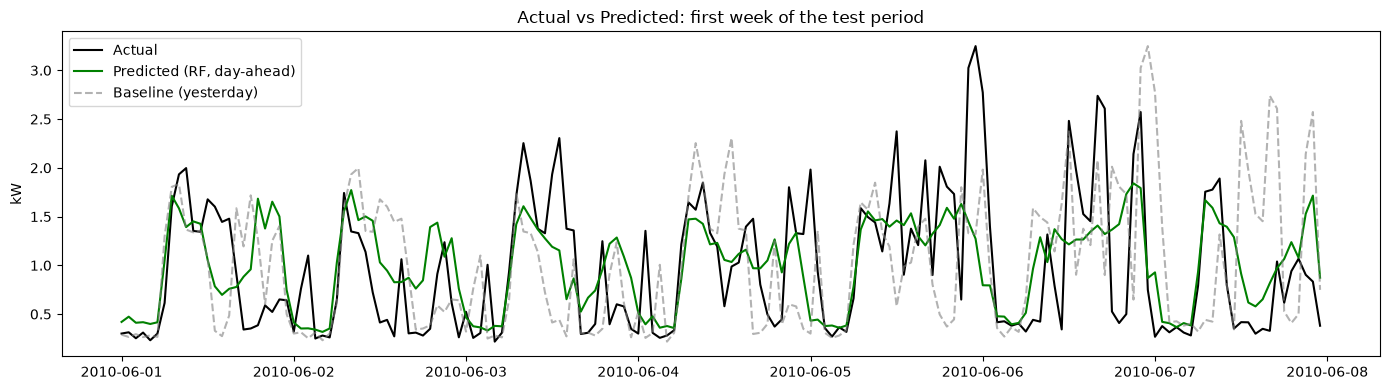

In [24]:
week = te.iloc[:168]
pred_week = m0.predict(week[f0])

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(week.index, week[TARGET], label="Actual", color="black")
ax.plot(week.index, pred_week, label="Predicted (RF, day-ahead)", color="green")
ax.plot(week.index, week["lag_24"], label="Baseline (yesterday)",
        color="gray", linestyle="--", alpha=0.6)
ax.set_ylabel("kW")
ax.set_title("Actual vs Predicted: first week of the test period")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "actual_vs_predicted_week.png", dpi=150)
plt.show()

## 11. Monthly bill estimate

The tariff is kept in `config.json` (tiered prices per kWh), so it can be changed without touching the code. `monthly_bill` applies the tiers to a total in kWh. As an example, the model's predictions for 30 days of the test period are summed to kWh, converted to money, and compared with the bill computed from the real consumption.

In [25]:
CONFIG = OUT / "config.json"
DEFAULT_CFG = {
    "currency": "EGP",
    "tiers": [
        {"up_to_kwh": 50,   "price": 0.68},
        {"up_to_kwh": 100,  "price": 0.87},
        {"up_to_kwh": 200,  "price": 1.00},
        {"up_to_kwh": 350,  "price": 1.73},
        {"up_to_kwh": 650,  "price": 2.18},
        {"up_to_kwh": 1000, "price": 2.35},
        {"up_to_kwh": None, "price": 2.89},
    ],
}
if not CONFIG.exists():
    CONFIG.write_text(json.dumps(DEFAULT_CFG, indent=2))
cfg = json.loads(CONFIG.read_text())


def monthly_bill(kwh, tiers):
    total, lower = 0.0, 0.0
    for t in tiers:
        upper = float("inf") if t["up_to_kwh"] is None else t["up_to_kwh"]
        total += max(0.0, min(kwh, upper) - lower) * t["price"]
        lower = upper
        if kwh <= upper:
            break
    return total


month = te.iloc[: 24 * 30]
pred_kwh = m0.predict(month[f0]).sum()
actual_kwh = month[TARGET].sum()

pred_bill = monthly_bill(pred_kwh, cfg["tiers"])
actual_bill = monthly_bill(actual_kwh, cfg["tiers"])

print(f"Predicted : {pred_kwh:8.1f} kWh -> {pred_bill:8.2f} {cfg['currency']}")
print(f"Actual    : {actual_kwh:8.1f} kWh -> {actual_bill:8.2f} {cfg['currency']}")
print(f"kWh error : {abs(pred_kwh - actual_kwh) / actual_kwh * 100:.1f}%")
print(f"Bill error: {abs(pred_bill - actual_bill) / actual_bill * 100:.1f}%")

Predicted :    728.4 kWh ->  1275.20 EGP
Actual    :    698.1 kWh ->  1204.10 EGP
kWh error : 4.3%
Bill error: 5.9%


## 12. Save the model

Save the day-ahead model with `joblib`, together with its feature list and the scikit-learn version it was trained with, so `predict.py` can check that the versions match.

In [26]:
joblib.dump({"model": m0, "features": f0, "sklearn_version": sklearn.__version__},
            OUT / "forecast_model.joblib")
print(round((OUT / "forecast_model.joblib").stat().st_size / 1e6, 1), "MB")

48.7 MB


## 13. Write `predict.py`

A standalone script with `predict(history)`: it takes the recent hourly history (at least 192 hours) and returns the forecast for the next 24 hours. It builds the same features as this notebook and works on a fresh CSV without the notebook:

    python predict.py history.csv

In [27]:
PREDICT_PY = '''import sys
import warnings
from pathlib import Path

import joblib
import pandas as pd

MODEL_PATH = Path(__file__).with_name("forecast_model.joblib")
MIN_HISTORY = 192


def predict(history, col="Global_active_power"):
    bundle = joblib.load(MODEL_PATH)
    model, feats = bundle["model"], bundle["features"]

    saved = bundle.get("sklearn_version")
    if saved:
        import sklearn
        if saved != sklearn.__version__:
            warnings.warn(f"model saved with scikit-learn {saved}, "
                          f"running {sklearn.__version__}")

    y = history[col] if isinstance(history, pd.DataFrame) else history
    y = y.astype(float).sort_index().asfreq("1h").ffill()
    if len(y) < MIN_HISTORY:
        raise ValueError(f"need at least {MIN_HISTORY} hours of history, got {len(y)}")

    h = pd.Timedelta(hours=1)
    idx = pd.date_range(y.index[-1] + h, periods=24, freq="1h")

    rows = []
    for t in idx:
        rows.append({
            "hour": t.hour,
            "weekday": t.day_of_week,
            "is_weekend": int(t.day_of_week >= 5),
            "lag_24": y.loc[t - 24 * h],
            "lag_48": y.loc[t - 48 * h],
            "lag_168": y.loc[t - 168 * h],
            "roll_24": y.loc[t - 47 * h: t - 24 * h].mean(),
            "roll_168": y.loc[t - 191 * h: t - 24 * h].mean(),
        })
    X = pd.DataFrame(rows, index=idx)[feats]
    return pd.Series(model.predict(X), index=idx, name="forecast_kW")


if __name__ == "__main__":
    if len(sys.argv) != 2:
        sys.exit("Usage: python predict.py history.csv")
    hist = pd.read_csv(sys.argv[1], index_col=0, parse_dates=True)
    print(predict(hist).round(3).to_string())
'''
(OUT / "predict.py").write_text(PREDICT_PY, encoding="utf-8")
print("saved:", OUT / "predict.py")

saved: d:\Hass\energy\predict.py


## 14. Check that `predict.py` matches the notebook

Pick a full day from the test period, give `predict()` the history before it, and compare its output with the notebook model's predictions for the same day. The difference must be about zero, otherwise the script builds the features differently from the notebook.

In [28]:
sys.path.insert(0, str(OUT))
import predict
importlib.reload(predict)

# pick a day in the test period that has all 24 hours; the history before it is then gap-free
per_day = te.index.normalize().value_counts()
full_days = sorted(per_day[per_day == 24].index)
day = full_days[len(full_days) // 2]
cut = day - pd.Timedelta(hours=1)
print("forecast day:", day.date())

fc = predict.predict(df.loc[:cut, [TARGET]])

ref = pd.Series(m0.predict(te.loc[fc.index, f0]), index=fc.index)
diff = float((fc - ref).abs().max())
print("max diff vs notebook:", diff)
assert diff < 1e-9, "predict.py does not match the notebook"

forecast day: 2010-08-16
max diff vs notebook: 6.661338147750939e-16


## Summary

- Time-based split: train until Nov 2009, validation Dec 2009 to May 2010, test from Jun 2010.
- Next-hour forecast: XGBoost MAE 0.3144 and Random Forest MAE 0.3169, versus 0.4879 for the "yesterday" baseline.
- Day-ahead forecast (used by the app): Random Forest MAE 0.4234 versus 0.4870 for "yesterday".
- The validation period (winter) is harder than the test period, so its errors are higher.
- Example monthly bill estimate: see cell 11.